# Part D: Differential Privacy and Secure Aggregation

差分隐私（Differential privacy）:限制结果透露单个贡献的信息，目标是：某张图片或某个客户端是否参与，都不会让发布结果的概率分布发生过大变化。

安全聚合（Secure aggregation）：安全聚合使用密码学协议，让服务器获得聚合结果，同时在协议的安全假设下看不到单个客户端的更新。

Privacy budget ε: 衡量差分隐私保证允许多大的隐私损失。

隐私损失：某条数据参与训练后，发布结果让别人获得了多少关于这条数据的额外信息。

在其他条件相同时：
- 越小：隐私保证越强，更难区分某个样本或客户端是否参与训练。
- 越大：隐私保证越弱，通常更容易保留模型效果。

Privacy parameter δ：是差分隐私定义中的一个额外概率容差，通常设置得很小。

Sensitivity：敏感度，改变一个受保护单位的数据，最多能让计算结果改变多少。

Gradient or update clipping：梯度或更新裁剪，用于限制一个样本或客户端的贡献有多大。

Gaussian noise：高斯噪声，就是从正态分布中抽取的随机数，然后加到梯度、更新或聚合结果中。攻击者看到的是扰动后的结果，因此更难精确识别单个贡献。

Privacy accountant：隐私会计器，它是一个计算和跟踪累计隐私损失的工具。
你的客户端可能参与很多轮训练，每轮都有信息被发布，隐私损失会累积。
会计器根据机制中的信息计算最终预算，例如：
- 噪声强度。
- 样本或客户端的抽样概率。
- 更新或发布的次数。

Central differential privacy：中央差分隐私
经典中央 DP 依赖一个可信的聚合方，由它处理敏感信息，并在发布结果前加入经过校准的噪声。

客户端更新 → 可信服务器聚合并加噪 → 发布全局模型

Local differential privacy：本地差分隐私
本地 DP 要求：信息离开数据拥有者之前，就已经经过随机化并满足所声明的 DP 保证。

客户端本地随机化 → 上传受保护的信息 → 服务器聚合

Sample-level privacy：样本级隐私
保护单位是一个训练样本。

Client-level privacy：客户端级隐私
保护单位是一个客户端的全部数据或整体贡献。

In [1]:
#数据导入
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import (
    DataLoader,
    TensorDataset,
    Subset,
    random_split
)
from torchvision.datasets import MNIST

from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)


SEED = 42

NUM_CLIENTS = 5

ROUNDS = 10
LOCAL_EPOCHS = 10

BATCH_SIZE = 128
LR = 0.001

HIDDEN_DIM = 128
LATENT_DIM = 16
NUM_CLUSTERS = 5

DEVICE = torch.device("cpu")

# 固定裁剪上限，比较不同噪声倍率
CLIP_NORM = 1.0
NOISE_MULTIPLIERS = [0.0, 0.01, 0.05, 0.10]

# Silhouette 最多使用多少个测试样本
SILHOUETTE_MAX_SAMPLES = 2000

torch.manual_seed(SEED)
torch.set_num_threads(4)

In [2]:
project_root = Path.cwd()

if project_root.name == "week4":
    project_root = project_root.parent

data_root = project_root / "data"

MNIST.mirrors = [
    "https://storage.googleapis.com/cvdf-datasets/mnist/"
]

raw_train = MNIST(
    root=data_root,
    train=True,
    download=True
)

raw_test = MNIST(
    root=data_root,
    train=False,
    download=True
)

train_data = TensorDataset(
    raw_train.data.float().unsqueeze(1) / 255.0,
    raw_train.targets
)

test_data = TensorDataset(
    raw_test.data.float().unsqueeze(1) / 255.0,
    raw_test.targets
)

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

Training samples: 60000
Test samples: 10000


In [3]:
#划分数据
def make_loader(
    dataset,
    shuffle=False,
    seed=SEED,
    batch_size=BATCH_SIZE
):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        generator=torch.Generator().manual_seed(seed)
    )


# IID：随机平均划分
iid_clients = random_split(
    train_data,
    [0.2] * NUM_CLIENTS,
    generator=torch.Generator().manual_seed(SEED)
)


# non-IID：每个客户端包含两个数字类别
labels = train_data.tensors[1]

non_iid_clients = []

for client_id in range(NUM_CLIENTS):
    digit1 = 2 * client_id
    digit2 = 2 * client_id + 1

    mask = (labels == digit1) | (labels == digit2)
    indices = torch.where(mask)[0].tolist()

    client_data = Subset(train_data, indices)
    non_iid_clients.append(client_data)


# 全局 K-means 使用训练集特征进行拟合
train_eval_loader = make_loader(
    train_data,
    batch_size=1024
)

# 在完整测试集上计算指标
test_loader = make_loader(
    test_data,
    batch_size=1024
)


print("IID client sizes:")
print([len(client) for client in iid_clients])

print("\nnon-IID client sizes:")
print([len(client) for client in non_iid_clients])

IID client sizes:
[12000, 12000, 12000, 12000, 12000]

non-IID client sizes:
[12665, 12089, 11263, 12183, 11800]


In [4]:
#定义 Autoencoder
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, 784),
            nn.Sigmoid()
        )

    def forward(self, images):
        features = self.encoder(images)
        reconstructed = self.decoder(features)

        return reconstructed.reshape_as(images)


initial_ae = Autoencoder()

initial_state = copy.deepcopy(
    initial_ae.state_dict()
)


def new_ae():
    model = Autoencoder().to(DEVICE)
    model.load_state_dict(initial_state)

    return model

In [5]:
#定义客户端的本地训练函数
def train_ae(model, loader, epochs):
    model.train()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    criterion = nn.MSELoss()

    for epoch in range(epochs):
        for images, _ in loader:
            images = images.to(DEVICE)

            optimizer.zero_grad()

            reconstructed = model(images)
            loss = criterion(reconstructed, images)

            loss.backward()
            optimizer.step()

In [6]:
#提取编码特征，计算重建误差
@torch.no_grad()
def extract_features_and_loss(model, loader):
    model.eval()

    all_features = []
    all_labels = []

    squared_error = 0.0
    pixel_count = 0

    for images, labels in loader:
        images = images.to(DEVICE)

        features = model.encoder(images)

        reconstructed = model.decoder(features)
        reconstructed = reconstructed.reshape_as(images)

        all_features.append(
            features.cpu().numpy()
        )

        all_labels.append(
            labels.numpy()
        )

        squared_error += (
            (reconstructed - images) ** 2
        ).sum().item()

        pixel_count += images.numel()

    features = np.concatenate(
        all_features,
        axis=0
    )

    labels = np.concatenate(
        all_labels,
        axis=0
    )

    reconstruction_loss = squared_error / pixel_count

    return features, labels, reconstruction_loss

In [7]:
#定义聚类评估函数
def calculate_silhouette(features, clusters):
    if (
        SILHOUETTE_MAX_SAMPLES is not None
        and len(features) > SILHOUETTE_MAX_SAMPLES
    ):
        rng = np.random.default_rng(SEED)

        indices = rng.choice(
            len(features),
            size=SILHOUETTE_MAX_SAMPLES,
            replace=False
        )

        features = features[indices]
        clusters = clusters[indices]

    number_of_clusters = len(
        np.unique(clusters)
    )

    # 至少两个簇，且不能每个样本都单独成簇
    if not 2 <= number_of_clusters < len(features):
        return np.nan

    return silhouette_score(
        features,
        clusters
    )


def evaluate_pipeline(
    model,
    fit_loader,
    evaluation_loader
):
    # 提取训练特征，不使用训练标签
    Z_train, _, _ = extract_features_and_loss(
        model,
        fit_loader
    )

    # 提取测试特征和标签
    Z_eval, y_eval, reconstruction_loss = (
        extract_features_and_loss(
            model,
            evaluation_loader
        )
    )

    kmeans = KMeans(
        n_clusters=NUM_CLUSTERS,
        n_init=10,
        random_state=SEED
    )

    kmeans.fit(Z_train)

    clusters = kmeans.predict(Z_eval)

    return {
        "ARI": adjusted_rand_score(
            y_eval,
            clusters
        ),
        "NMI": normalized_mutual_info_score(
            y_eval,
            clusters
        ),
        "Silhouette": calculate_silhouette(
            Z_eval,
            clusters
        ),
        "Reconstruction_loss": reconstruction_loss
    }

In [8]:
#计算并裁剪每个客户端的模型更新
def clip_client_update(
    local_state,
    global_state,
    clip_norm
):
    # 本地训练后的参数 - 本轮全局参数
    update = {
        name: local_state[name] - global_state[name]
        for name in global_state
    }

    # 整个更新向量的 L2 范数
    norm_before = torch.sqrt(sum(
        value.square().sum()
        for value in update.values()
    )).item()

    if norm_before > 0:
        scale = min(
            1.0,
            clip_norm / norm_before
        )
    else:
        scale = 1.0

    # 所有参数使用相同的缩放比例
    clipped_update = {
        name: value * scale
        for name, value in update.items()
    }

    norm_after = torch.sqrt(sum(
        value.square().sum()
        for value in clipped_update.values()
    )).item()

    return clipped_update, norm_before, norm_after

In [9]:
#实现裁剪和加噪的联邦训练
def train_federated_with_noise(
    client_sets,
    noise_multiplier,
    clip_norm=CLIP_NORM,
    rounds=ROUNDS,
    local_epochs=LOCAL_EPOCHS,
    partition="unknown"
):
    torch.manual_seed(SEED)

    # 每组实验从相同初始参数开始
    global_ae = new_ae()

    # 每组实验重建 loader，保持数据顺序一致
    client_loaders = [
        make_loader(
            client,
            shuffle=True,
            seed=SEED + client_id
        )
        for client_id, client in enumerate(client_sets)
    ]

    total_samples = sum(
        len(client) for client in client_sets
    )

    # 噪声使用单独的随机数生成器
    noise_generator = torch.Generator(
        device=DEVICE
    ).manual_seed(SEED + 1000)

    norm_records = []

    for round_id in range(1, rounds + 1):
        global_state = copy.deepcopy(
            global_ae.state_dict()
        )

        averaged_update = {
            name: torch.zeros_like(value)
            for name, value in global_state.items()
        }

        for client_id, loader in enumerate(client_loaders):
            # 每个客户端获得本轮相同的全局模型
            local_ae = copy.deepcopy(global_ae)

            train_ae(
                model=local_ae,
                loader=loader,
                epochs=local_epochs
            )

            # 计算并裁剪本地更新
            clipped_update, norm_before, norm_after = (
                clip_client_update(
                    local_state=local_ae.state_dict(),
                    global_state=global_state,
                    clip_norm=clip_norm
                )
            )

            # 按客户端样本数加权
            weight = len(loader.dataset) / total_samples

            for name in averaged_update:
                averaged_update[name] += (
                    weight * clipped_update[name]
                )

            norm_records.append({
                "Round": round_id,
                "Client": client_id,
                "Update_norm_before": norm_before,
                "Update_norm_after": norm_after
            })

        # 对加权平均更新加入高斯噪声
        noise_std = noise_multiplier * clip_norm

        for name, update in averaged_update.items():
            noise = torch.randn(
                update.shape,
                generator=noise_generator,
                device=update.device,
                dtype=update.dtype
            ) * noise_std

            # 新参数 = 旧参数 + 平均更新 + 噪声
            global_state[name] += update + noise

        global_ae.load_state_dict(global_state)

        print(
            f"[{partition}] sigma={noise_multiplier:.2f}: "
            f"round {round_id}/{rounds}"
        )

    return global_ae, pd.DataFrame(norm_records)

In [10]:
#运行对比实验
result_records = []
all_norm_records = []

for partition, client_sets in [
    ("IID", iid_clients),
    ("non-IID", non_iid_clients)
]:
    for sigma in NOISE_MULTIPLIERS:
        model, norm_details = train_federated_with_noise(
            client_sets=client_sets,
            noise_multiplier=sigma,
            partition=partition
        )

        scores = evaluate_pipeline(
            model=model,
            fit_loader=train_eval_loader,
            evaluation_loader=test_loader
        )

        result_records.append({
            "Partition": partition,
            "Noise_multiplier": sigma,
            "Clip_norm": CLIP_NORM,
            **scores,
            "Update_norm_before_mean": (
                norm_details["Update_norm_before"].mean()
            ),
            "Update_norm_after_mean": (
                norm_details["Update_norm_after"].mean()
            )
        })

        all_norm_records.append(
            norm_details.assign(
                Partition=partition,
                Noise_multiplier=sigma
            )
        )

results = pd.DataFrame(result_records)

update_norm_details = pd.concat(
    all_norm_records,
    ignore_index=True
)

[IID] sigma=0.00: round 1/10
[IID] sigma=0.00: round 2/10
[IID] sigma=0.00: round 3/10
[IID] sigma=0.00: round 4/10
[IID] sigma=0.00: round 5/10
[IID] sigma=0.00: round 6/10
[IID] sigma=0.00: round 7/10
[IID] sigma=0.00: round 8/10
[IID] sigma=0.00: round 9/10
[IID] sigma=0.00: round 10/10
[IID] sigma=0.01: round 1/10
[IID] sigma=0.01: round 2/10
[IID] sigma=0.01: round 3/10
[IID] sigma=0.01: round 4/10
[IID] sigma=0.01: round 5/10
[IID] sigma=0.01: round 6/10
[IID] sigma=0.01: round 7/10
[IID] sigma=0.01: round 8/10
[IID] sigma=0.01: round 9/10
[IID] sigma=0.01: round 10/10
[IID] sigma=0.05: round 1/10
[IID] sigma=0.05: round 2/10
[IID] sigma=0.05: round 3/10
[IID] sigma=0.05: round 4/10
[IID] sigma=0.05: round 5/10
[IID] sigma=0.05: round 6/10
[IID] sigma=0.05: round 7/10
[IID] sigma=0.05: round 8/10
[IID] sigma=0.05: round 9/10
[IID] sigma=0.05: round 10/10
[IID] sigma=0.10: round 1/10
[IID] sigma=0.10: round 2/10
[IID] sigma=0.10: round 3/10
[IID] sigma=0.10: round 4/10
[IID] sigma

In [11]:
from IPython.display import display

comparison_table = results[
    [
        "Partition",
        "Reconstruction_loss",
        "ARI",
        "NMI",
        "Silhouette",
        "Update_norm_before_mean",
        "Update_norm_after_mean",
        "Noise_multiplier"
    ]
].rename(
    columns={
        "Reconstruction_loss": "Reconstruction loss",
        "Silhouette": "Silhouette score",
        "Update_norm_before_mean": "Update norm before clipping",
        "Update_norm_after_mean": "Update norm after clipping",
        "Noise_multiplier": "Noise multiplier"
    }
)

display(comparison_table.round(4))

,Partition,Reconstruction loss,ARI,NMI,Silhouette score,Update norm before clipping,Update norm after clipping,Noise multiplier
0,IID,0.1609,0.2788,0.3823,0.1264,25.4736,1.0,0.00
1,IID,0.1568,0.1824,0.2839,0.1175,25.6244,1.0,0.01
2,IID,0.2878,0.1781,0.2432,0.1065,25.8532,1.0,0.05
3,IID,0.4182,0.1491,0.2137,0.0927,26.7963,1.0,0.10
4,non-IID,0.1687,0.2257,0.3170,0.1294,25.2125,1.0,0.00
5,non-IID,0.1637,0.1603,0.2302,0.1201,24.9593,1.0,0.01
6,non-IID,0.2859,0.1562,0.2175,0.1013,25.5788,1.0,0.05
7,non-IID,0.4167,0.1345,0.1934,0.0901,25.7277,1.0,0.10


噪声增大后，聚类指标持续下降，sigma=0.01 的重建更好，但聚类更差

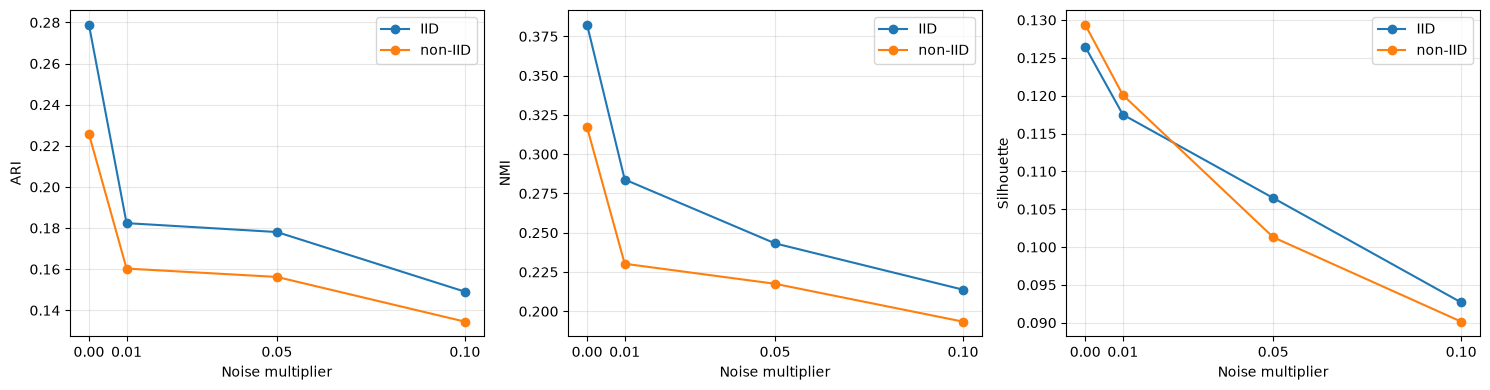

In [12]:
#画出噪声倍率与聚类表现的关系
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4)
)

for ax, metric in zip(
    axes,
    ["ARI", "NMI", "Silhouette"]
):
    for partition in ["IID", "non-IID"]:
        rows = results[
            results["Partition"] == partition
        ].sort_values("Noise_multiplier")

        ax.plot(
            rows["Noise_multiplier"],
            rows[metric],
            marker="o",
            label=partition
        )

    ax.set_xlabel("Noise multiplier")
    ax.set_ylabel(metric)

    ax.set_xticks(NOISE_MULTIPLIERS)

    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Why is clipping needed before adding noise?

Ans:Clipping limits how much one client can influence the aggregated update, so we can choose an appropriate noise level.

What is the privacy–utility trade-off?

Ans:The privacy–utility trade-off is the balance between protecting individual information and maintaining model performance.

Why does a noise multiplier alone not fully specify a differential privacy guarantee?

Ans:A noise multiplier only specifies the noise scale relative to the clipping bound. A differential privacy guarantee also depends on the protected unit, the definition of neighboring datasets, the sensitivity of the aggregation, the sampling process, and the number of training rounds.

What is the difference between sample-level and client-level privacy?

Ans:Sample-level privacy protects the contribution of one training example, such as a single image. Client-level privacy protects the entire contribution of one client, including all of its training data.

What problem does secure aggregation solve that noise addition does not?

Ans:Secure aggregation hides individual client updates from the aggregation server while allowing it to compute their sum.